In [3]:
import sys

!{sys.executable} -m pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.2 MB 3.1 MB/s eta 0:00:03
   ------ --------------------------------- 1.3/8.2 MB 4.8 MB/s eta 0:00:02
   -------- ------------------------------- 1.8/8.2 MB 3.9 MB/s eta 0:00:02
   ---------- ----------------------------- 2.1/8.2 MB 3.4 MB/s eta 0:00:02
   -------------- ------------------------- 2.9/8.2 MB 3.1 MB/s eta 0:00:02
   ---------------- ----------------------- 3.4/8.2 MB 2.8 MB/s eta 0:00:02
   -------------------- ------------------- 4.2/8.2 MB 3.0 MB/s eta 0:00:02
   --------------------- ------------------ 4.5/8.2 MB 2.9 MB/s eta 0:00:02
   ------------------------ --------------- 5.0/8.2 MB 2.8 MB/s eta 0:00:02
   ------------------------- -------------- 5.2/8.2 MB 2.7 MB/s eta 0:00:02
   ---------------------

In [4]:
import sklearn

print("scikit-learn installed successfully!")
print("Version:", sklearn.__version__)

scikit-learn installed successfully!
Version: 1.9.1


In [5]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

data = pd.DataFrame({
    'A': [10, 20, 30, 40, 50],
    'B': [5, 15, 25, 35, 45]
})

scaler = MinMaxScaler()

normalized_data = scaler.fit_transform(data)

normalized_df = pd.DataFrame(
    normalized_data,
    columns=data.columns
)

print("Original Data:")
print(data)

print("\nNormalized Data:")
print(normalized_df)

Original Data:
    A   B
0  10   5
1  20  15
2  30  25
3  40  35
4  50  45

Normalized Data:
      A     B
0  0.00  0.00
1  0.25  0.25
2  0.50  0.50
3  0.75  0.75
4  1.00  1.00


In [6]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

data = pd.DataFrame({
    'A': [10, 20, 30, 40, 50],
    'B': [5, 15, 25, 35, 45]
})

scaler = StandardScaler()

standardized_data = scaler.fit_transform(data)

standardized_df = pd.DataFrame(
    standardized_data,
    columns=data.columns
)

print("Standardized Data:")
print(standardized_df)

Standardized Data:
          A         B
0 -1.414214 -1.414214
1 -0.707107 -0.707107
2  0.000000  0.000000
3  0.707107  0.707107
4  1.414214  1.414214


In [7]:
import pandas as pd

df = pd.DataFrame({
    'Color': ['Red', 'Blue', 'Green', 'Red', 'Blue']
})

one_hot = pd.get_dummies(df, columns=['Color'])

print("Original Data:")
print(df)

print("\nOne-Hot Encoded Data:")
print(one_hot)

Original Data:
   Color
0    Red
1   Blue
2  Green
3    Red
4   Blue

One-Hot Encoded Data:
   Color_Blue  Color_Green  Color_Red
0       False        False       True
1        True        False      False
2       False         True      False
3       False        False       True
4        True        False      False


In [9]:
import sys

!{sys.executable} -m pip install pandas seaborn matplotlib scikit-learn

Defaulting to user installation because normal site-packages is not writeable


In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("All packages are working!")
print("Pandas:", pd.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)

All packages are working!
Pandas: 2.3.3
Seaborn: 0.13.2
Scikit-learn: 1.9.1


Explained Variance Ratio:
[0.72627656 0.1730423 ]

PCA Result:
        PC1       PC2
0 -1.348415  0.426746
1 -0.955740  1.093576
2  0.540971  0.122324
3  0.067789 -0.674616
4  1.408308  0.847661


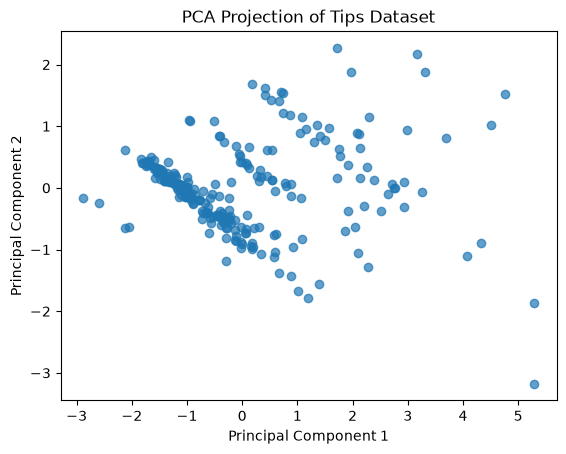

In [11]:
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

tips = sns.load_dataset("tips")

numeric_cols = tips.select_dtypes(
    include=['float64', 'int64']
)

scaler = StandardScaler()
scaled_data = scaler.fit_transform(numeric_cols)

pca = PCA(n_components=2)

pca_result = pca.fit_transform(scaled_data)

pca_df = pd.DataFrame(
    pca_result,
    columns=['PC1', 'PC2']
)

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nPCA Result:")
print(pca_df.head())

plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Projection of Tips Dataset")
plt.show()

Explained Variance Ratio:
[0.9912126 0.0087874]

LDA Result:
        LD1       LD2  target
0  8.143648 -0.303471       0
1  7.201062  0.794647       0
2  7.565869  0.268079       0
3  6.882372  0.677440       0
4  8.214873 -0.519686       0


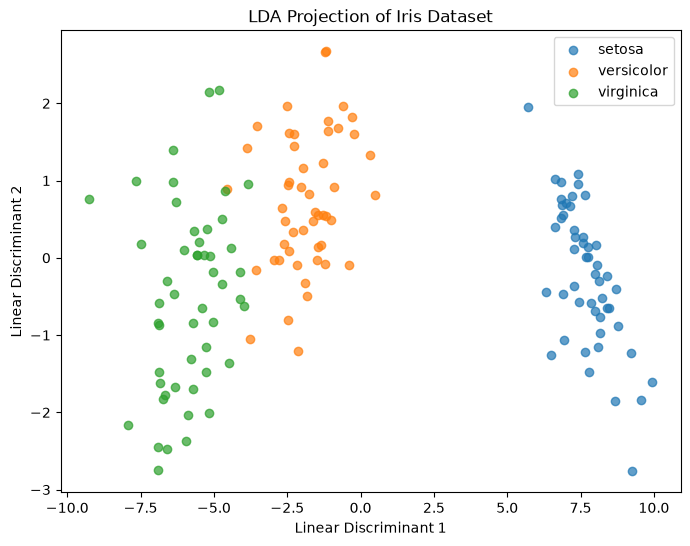

In [12]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
import matplotlib.pyplot as plt

iris = load_iris()

X = iris.data
y = iris.target

lda = LinearDiscriminantAnalysis(n_components=2)

X_lda = lda.fit_transform(X, y)

lda_df = pd.DataFrame(
    X_lda,
    columns=['LD1', 'LD2']
)

lda_df['target'] = y

print("Explained Variance Ratio:")
print(lda.explained_variance_ratio_)

print("\nLDA Result:")
print(lda_df.head())

plt.figure(figsize=(8, 6))

for label in [0, 1, 2]:
    plt.scatter(
        lda_df.loc[lda_df['target'] == label, 'LD1'],
        lda_df.loc[lda_df['target'] == label, 'LD2'],
        label=iris.target_names[label],
        alpha=0.7
    )

plt.xlabel("Linear Discriminant 1")
plt.ylabel("Linear Discriminant 2")
plt.title("LDA Projection of Iris Dataset")
plt.legend()
plt.show()

t-SNE Result:
       TSNE1     TSNE2  target
0 -25.502390 -1.643927       0
1 -23.042055 -0.994582       0
2 -22.787239 -2.096912       0
3 -22.498199 -1.861895       0
4 -25.574633 -2.148222       0


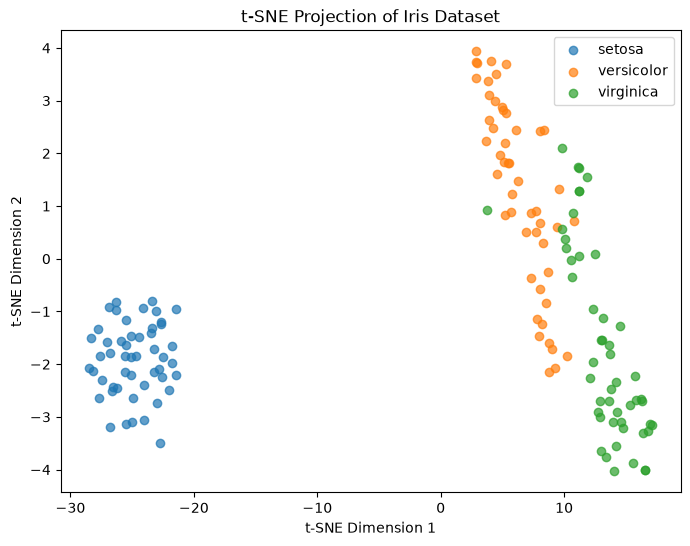

In [13]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

iris = load_iris()

X = iris.data
y = iris.target

tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    max_iter=1000
)

X_tsne = tsne.fit_transform(X)

tsne_df = pd.DataFrame(
    X_tsne,
    columns=['TSNE1', 'TSNE2']
)

tsne_df['target'] = y

print("t-SNE Result:")
print(tsne_df.head())

plt.figure(figsize=(8, 6))

for label in [0, 1, 2]:
    plt.scatter(
        tsne_df.loc[tsne_df['target'] == label, 'TSNE1'],
        tsne_df.loc[tsne_df['target'] == label, 'TSNE2'],
        label=iris.target_names[label],
        alpha=0.7
    )

plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.title("t-SNE Projection of Iris Dataset")
plt.legend()
plt.show()